# 06. Entrenamiento del modelo LSTM para ET₀

Primer modelo LSTM para predecir la evapotranspiración de referencia (ET₀) del **día siguiente** a partir de los **siete días anteriores** en la estación Tibaitatá.

- **Entrada:** `(n_secuencias, 7, 6)` con las variables `RH_mean`, `Radiation_Wh_m2`, `Tmax`, `Tmin`, `Wind_speed`, `T_mean`.
- **Salida:** ET₀ del día siguiente, escalada a [0, 1] con `scaler_y`.
- **Datos:** generados en `05_preparacion_LSTM.ipynb` (`./Datasets/LSTM/`). El escalado se ajustó solo con entrenamiento.

**Reglas de este notebook**

1. El conjunto de **entrenamiento** ajusta los pesos.
2. El conjunto de **validación** controla el Early Stopping.
3. El conjunto de **prueba** se usa una sola vez, al final, para informar el resultado. No se usa para elegir hiperparámetros ni para detener el entrenamiento.

> Los datos de la etapa 05 están en archivos `.npy` por conjunto y los escaladores en `.joblib` (no en un único `.npz` ni `.pkl`).

## 1. Importación de librerías

`numpy`/`pandas` para los datos, `joblib` para leer los escaladores, `matplotlib` para las gráficas, `scikit-learn` para las métricas en unidades originales y `tensorflow.keras` para el modelo.

In [1]:
import json
import os
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras
from tensorflow.keras import callbacks, layers

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
print("GPU disponible:", [d.name for d in tf.config.list_physical_devices("GPU")] or "no (se usa CPU)")

ModuleNotFoundError: No module named 'tensorflow'

### Parámetros y semilla aleatoria

Se fija la misma semilla en Python, NumPy y TensorFlow, y se activan operaciones deterministas. Con esto, dos ejecuciones en la misma máquina y con las mismas versiones deberían dar el mismo resultado. Entre máquinas o versiones distintas pueden aparecer diferencias pequeñas.

Los parámetros de entrenamiento son los indicados para este primer modelo. La paciencia del Early Stopping (10 épocas) es un valor fijo de partida, no se ajustó con datos de prueba.

In [ ]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)            # fija random, numpy y tensorflow a la vez
tf.config.experimental.enable_op_determinism()

# Rutas (relativas a la carpeta de este notebook, igual que en 05)
DIR_DATOS = Path("./Datasets/LSTM")
DIR_MODELOS = Path("./Models")
RUTA_MODELO = DIR_MODELOS / "lstm_et0.keras"
RUTA_HISTORIAL = DIR_MODELOS / "historial_lstm_et0.csv"

# Estructura esperada de los datos
VENTANA = 7
N_FEATURES = 6
FEATURES = ["RH_mean", "Radiation_Wh_m2", "Tmax", "Tmin", "Wind_speed", "T_mean"]
TARGET = "ET0"
CONJUNTOS = ["train", "val", "test"]

# Hiperparámetros del primer modelo
UNIDADES_LSTM = 64
UNIDADES_DENSE = 32
MAX_EPOCAS = 50
BATCH_SIZE = 32
PACIENCIA = 10

print(f"Semilla: {SEED} | Directorio de datos: {DIR_DATOS.resolve()}")

Semilla: 42 | Directorio de datos: /home/nicopulido/ProyectosGrado/Prob_Proyecto_Grado/Tibaitata/Datasets/LSTM


## 2. Carga de los conjuntos de entrenamiento, validación y prueba

Se cargan `X_*`, `y_*` y las fechas del día objetivo de cada muestra, junto con los dos escaladores y el `config_lstm.json` de la etapa 05. Antes de cargar se comprueba que todos los archivos existan.

In [ ]:
archivos_requeridos = (
    [f"{p}_{c}.npy" for c in CONJUNTOS for p in ("X", "y", "fechas_objetivo")]
    + ["scaler_X.joblib", "scaler_y.joblib", "config_lstm.json"]
)
faltantes = [a for a in archivos_requeridos if not (DIR_DATOS / a).is_file()]
assert not faltantes, f"Faltan archivos en {DIR_DATOS.resolve()}: {faltantes}. Ejecute antes 05_preparacion_LSTM.ipynb."

X, y, fechas = {}, {}, {}
for c in CONJUNTOS:
    X[c] = np.load(DIR_DATOS / f"X_{c}.npy")
    y[c] = np.load(DIR_DATOS / f"y_{c}.npy")
    fechas[c] = np.load(DIR_DATOS / f"fechas_objetivo_{c}.npy")

scaler_X = joblib.load(DIR_DATOS / "scaler_X.joblib")
scaler_y = joblib.load(DIR_DATOS / "scaler_y.joblib")
config = json.loads((DIR_DATOS / "config_lstm.json").read_text(encoding="utf-8"))

print("Conjuntos cargados:", ", ".join(f"{c}={len(y[c])}" for c in CONJUNTOS))

Conjuntos cargados: train=1192, val=396, test=390


## 3. Verificación de dimensiones y consistencia

Se comprueba que:

- ningún conjunto esté vacío;
- las formas sean `(N, 7, 6)` para `X` y `(N, 1)` para `y`, con el mismo `N` en `X`, `y` y fechas;
- no haya `NaN` ni infinitos;
- el orden temporal sea train → val → test, sin solapamiento;
- los escaladores y el `config` coincidan con lo que espera este notebook.

Después se bloquea la escritura de `X_test` e `y_test` para que ninguna celda posterior pueda modificarlos por accidente.

In [ ]:
for c in CONJUNTOS:
    N = len(y[c])
    assert N > 0 and len(X[c]) > 0, f"El conjunto '{c}' está vacío"
    assert X[c].shape == (N, VENTANA, N_FEATURES), f"{c}: X tiene forma {X[c].shape}, se esperaba ({N}, {VENTANA}, {N_FEATURES})"
    assert y[c].shape == (N, 1), f"{c}: y tiene forma {y[c].shape}, se esperaba ({N}, 1)"
    assert fechas[c].shape == (N,), f"{c}: fechas tiene forma {fechas[c].shape}, se esperaba ({N},)"
    assert np.isfinite(X[c]).all() and np.isfinite(y[c]).all(), f"{c}: hay NaN o infinitos"
    assert np.all(np.diff(fechas[c]) > np.timedelta64(0, "D")), f"{c}: las fechas objetivo no son estrictamente crecientes"

# Orden cronológico sin solapamiento
assert fechas["train"].max() < fechas["val"].min() < fechas["val"].max() < fechas["test"].min(), \
    "Los conjuntos no están ordenados cronológicamente train < val < test"

# Escaladores y configuración
assert scaler_X.n_features_in_ == N_FEATURES, f"scaler_X espera {scaler_X.n_features_in_} variables"
assert scaler_y.n_features_in_ == 1, f"scaler_y espera {scaler_y.n_features_in_} variables"
assert config["features"] == FEATURES and config["target"] == TARGET and config["ventana"] == VENTANA, \
    "El config_lstm.json no coincide con las variables o la ventana de este notebook"
assert all(config["muestras"][c] == len(y[c]) for c in CONJUNTOS), "El número de muestras no coincide con config_lstm.json"

# Protección del conjunto de prueba contra escritura accidental
X["test"].setflags(write=False)
y["test"].setflags(write=False)

resumen = pd.DataFrame({
    "muestras": [len(y[c]) for c in CONJUNTOS],
    "forma_X": [str(X[c].shape) for c in CONJUNTOS],
    "forma_y": [str(y[c].shape) for c in CONJUNTOS],
    "dtype": [str(X[c].dtype) for c in CONJUNTOS],
    "fecha_objetivo_inicial": [str(fechas[c][0]) for c in CONJUNTOS],
    "fecha_objetivo_final": [str(fechas[c][-1]) for c in CONJUNTOS],
    "y_min": [float(y[c].min()) for c in CONJUNTOS],
    "y_max": [float(y[c].max()) for c in CONJUNTOS],
}, index=CONJUNTOS)
resumen

,muestras,forma_X,forma_y,dtype,fecha_objetivo_inicial,fecha_objetivo_final,y_min,y_max
train,1192,"(1192, 7, 6)","(1192, 1)",float32,2005-02-09,2019-03-02,0.000415,0.967726
val,396,"(396, 7, 6)","(396, 1)",float32,2019-03-03,2021-04-28,0.077564,0.942422
test,390,"(390, 7, 6)","(390, 1)",float32,2021-04-29,2022-10-31,0.084639,0.876486


Los valores de `y_min` y `y_max` están en escala [0, 1]. Como el escalador se ajustó solo con entrenamiento, validación y prueba pueden salirse de ese rango si contienen valores no vistos al entrenar. Esto es esperable y conviene tenerlo presente al interpretar el error.

## 4. Arquitectura LSTM inicial

| Capa | Configuración | Salida |
|---|---|---|
| `Input` | 7 días × 6 variables | `(7, 6)` |
| `LSTM` | 64 unidades | `(64,)` |
| `Dense` | 32 neuronas, ReLU | `(32,)` |
| `Dense` | 1 neurona, activación lineal | `(1,)` |

La salida es lineal porque se trata de una regresión. La LSTM devuelve solo el último estado (`return_sequences=False`), que resume los siete días y alimenta las capas densas.

In [ ]:
def construir_modelo():
    return keras.Sequential(
        [
            layers.Input(shape=(VENTANA, N_FEATURES), name="ventana_7d"),
            layers.LSTM(UNIDADES_LSTM, name="lstm_64"),
            layers.Dense(UNIDADES_DENSE, activation="relu", name="dense_32"),
            layers.Dense(1, name="et0_dia_siguiente"),
        ],
        name="lstm_et0",
    )

model = construir_modelo()
model.summary()

Model: "lstm_et0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_64 (LSTM)                  │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ et0_dia_siguiente (Dense)       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,289 (79.25 KB)

 Trainable params: 20,289 (79.25 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Compilación

- **Optimizador:** Adam con la tasa de aprendizaje por defecto (0.001).
- **Pérdida:** error cuadrático medio (MSE).
- **Métricas:** MAE y MSE. Con esta pérdida, `mse` y `loss` coinciden. Se deja `mse` como métrica por pedido explícito y como control.

Todas las métricas de esta etapa están en escala normalizada [0, 1]. En la etapa 9 se convierten a mm/día.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="mse",
    metrics=["mae", "mse"],
)
print("Modelo compilado. Parámetros entrenables:", f"{model.count_params():,}")

Modelo compilado. Parámetros entrenables: 20,289


## 6. Early Stopping

Se vigila `val_loss`. Si no mejora durante 10 épocas seguidas, el entrenamiento se detiene y se restauran los pesos de la mejor época (`restore_best_weights=True`). Así el modelo final no es el de la última época, sino el de menor pérdida de validación.

In [ ]:
early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=PACIENCIA,
    restore_best_weights=True,
    verbose=1,
)

## 7. Entrenamiento

Máximo 50 épocas con `batch_size=32`. Solo se pasan datos de entrenamiento a `fit` y los de validación como `validation_data`. El conjunto de prueba no aparece en esta celda.

`shuffle=True` (valor por defecto) mezcla las muestras de entrenamiento en cada época. Es correcto aquí porque cada muestra ya contiene su propia ventana de 7 días. Los conjuntos no se mezclan entre sí.

In [ ]:
history = model.fit(
    X["train"], y["train"],
    validation_data=(X["val"], y["val"]),
    epochs=MAX_EPOCAS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=2,
)

epocas_ejecutadas = len(history.history["loss"])
mejor_epoca = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nÉpocas ejecutadas: {epocas_ejecutadas} de {MAX_EPOCAS}")
print(f"Mejor época (menor val_loss): {mejor_epoca} | val_loss = {min(history.history['val_loss']):.6f}")

Epoch 1/50


E0000 00:00:1794888701.543248  501005 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


38/38 - 2s - 61ms/step - loss: 0.0534 - mae: 0.1806 - mse: 0.0534 - val_loss: 0.0282 - val_mae: 0.1379 - val_mse: 0.0282


Epoch 2/50


38/38 - 0s - 6ms/step - loss: 0.0275 - mae: 0.1336 - mse: 0.0275 - val_loss: 0.0256 - val_mae: 0.1299 - val_mse: 0.0256


Epoch 3/50


... (72 outputs left out)

38/38 - 0s - 6ms/step - loss: 0.0252 - mae: 0.1268 - mse: 0.0252 - val_loss: 0.0243 - val_mae: 0.1254 - val_mse: 0.0243


Epoch 39: early stopping


Restoring model weights from the end of the best epoch: 29.



Épocas ejecutadas: 39 de 50
Mejor época (menor val_loss): 29 | val_loss = 0.024314


## 8. Curvas de pérdida

Se grafican la pérdida (MSE) y el MAE de entrenamiento y validación por época. La línea vertical marca la época cuyos pesos se restauraron.

Cómo leerlas:
- Si `val_loss` sube mientras `loss` baja, hay sobreajuste.
- Si ambas se mantienen altas, el modelo es insuficiente o faltan variables.
- Una brecha estable entre validación y entrenamiento puede deberse al desfase temporal entre conjuntos (validación es posterior en el tiempo).

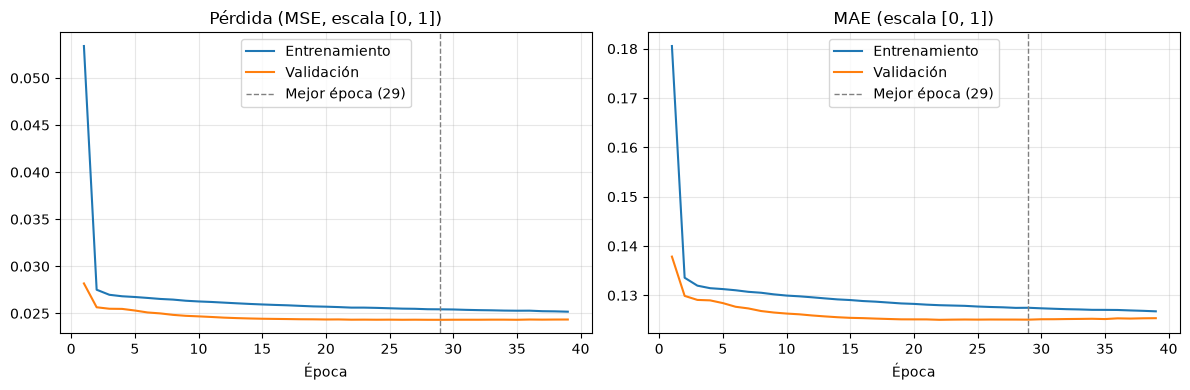

In [ ]:
hist = history.history
epocas = np.arange(1, len(hist["loss"]) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (clave, titulo) in zip(ejes, [("loss", "Pérdida (MSE, escala [0, 1])"), ("mae", "MAE (escala [0, 1])")]):
    ax.plot(epocas, hist[clave], label="Entrenamiento")
    ax.plot(epocas, hist[f"val_{clave}"], label="Validación")
    ax.axvline(mejor_epoca, color="gray", linestyle="--", linewidth=1, label=f"Mejor época ({mejor_epoca})")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Evaluación preliminar sobre el conjunto de prueba

Es la primera y única vez que el modelo ve el conjunto de prueba. El resultado **no debe usarse para ajustar hiperparámetros**: si se cambia el modelo a partir de estos números, la prueba deja de ser independiente.

Se informan dos grupos de métricas:
1. **Escala normalizada**, con `model.evaluate`.
2. **Unidades originales (mm/día)**, tras invertir el escalado con `scaler_y`.

In [ ]:
# 1) Métricas en escala normalizada
res_test = model.evaluate(X["test"], y["test"], batch_size=BATCH_SIZE, return_dict=True, verbose=0)
print("Prueba, escala normalizada:", {k: round(float(v), 6) for k, v in res_test.items()})

# 2) Métricas en mm/día
pred_esc = model.predict(X["test"], batch_size=BATCH_SIZE, verbose=0)
assert pred_esc.shape == y["test"].shape and np.isfinite(pred_esc).all()

y_real = scaler_y.inverse_transform(y["test"]).ravel()
y_pred = scaler_y.inverse_transform(pred_esc).ravel()

metricas_test = {
    "MAE (mm/día)": mean_absolute_error(y_real, y_pred),
    "RMSE (mm/día)": float(np.sqrt(mean_squared_error(y_real, y_pred))),
    "R²": r2_score(y_real, y_pred),
    "Sesgo medio (mm/día)": float(np.mean(y_pred - y_real)),
    "ET0 media observada (mm/día)": float(y_real.mean()),
}
pd.Series(metricas_test, name="Prueba").round(4).to_frame()

E0000 00:00:1794888713.132797  501005 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Prueba, escala normalizada: {'loss': 0.020491, 'mae': 0.115198, 'mse': 0.020491}


,Prueba
MAE (mm/día),0.4080
RMSE (mm/día),0.5070
R²,0.0125
Sesgo medio (mm/día),0.0629
ET0 media observada (mm/día),2.5719


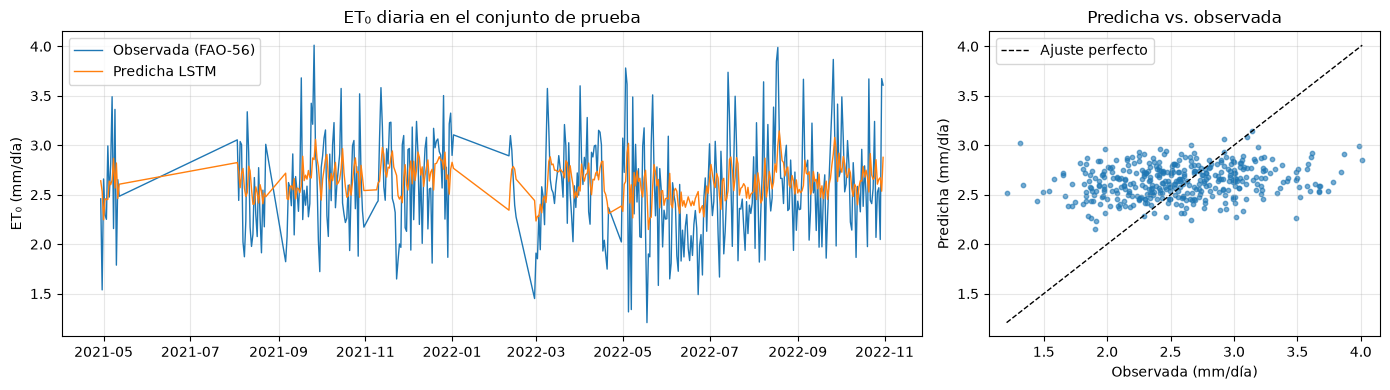

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})

ejes[0].plot(fechas["test"], y_real, label="Observada (FAO-56)", linewidth=1)
ejes[0].plot(fechas["test"], y_pred, label="Predicha LSTM", linewidth=1)
ejes[0].set_title("ET₀ diaria en el conjunto de prueba")
ejes[0].set_ylabel("ET₀ (mm/día)")
ejes[0].grid(alpha=0.3)
ejes[0].legend()

lim = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
ejes[1].scatter(y_real, y_pred, s=10, alpha=0.6)
ejes[1].plot(lim, lim, "k--", linewidth=1, label="Ajuste perfecto")
ejes[1].set_title("Predicha vs. observada")
ejes[1].set_xlabel("Observada (mm/día)")
ejes[1].set_ylabel("Predicha (mm/día)")
ejes[1].grid(alpha=0.3)
ejes[1].legend()

plt.tight_layout()
plt.show()

## 10. Guardado del modelo

Se guarda en formato `.keras` (arquitectura, pesos y configuración de compilación). Luego se recarga y se comprueba que produce las mismas predicciones sobre el conjunto de **validación**, para verificar el archivo sin volver a usar la prueba.

In [ ]:
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
model.save(RUTA_MODELO)

modelo_cargado = keras.models.load_model(RUTA_MODELO)
p_original = model.predict(X["val"], batch_size=BATCH_SIZE, verbose=0)
p_cargado = modelo_cargado.predict(X["val"], batch_size=BATCH_SIZE, verbose=0)
assert np.allclose(p_original, p_cargado, atol=1e-6), "El modelo recargado no reproduce las predicciones"

print(f"Modelo guardado en {RUTA_MODELO.resolve()} ({RUTA_MODELO.stat().st_size / 1024:.1f} KB). Verificación de recarga: OK")

Modelo guardado en /home/nicopulido/ProyectosGrado/Prob_Proyecto_Grado/Tibaitata/Models/lstm_et0.keras (266.3 KB). Verificación de recarga: OK


## 11. Guardado del historial de entrenamiento

Se guarda una fila por época con `loss`, `mae`, `mse` y sus equivalentes de validación (`val_*`), en CSV para poder reutilizarlo en notebooks posteriores sin reentrenar.

In [ ]:
df_hist = pd.DataFrame(history.history)
df_hist.insert(0, "epoca", np.arange(1, len(df_hist) + 1))
df_hist.to_csv(RUTA_HISTORIAL, index=False)

leido = pd.read_csv(RUTA_HISTORIAL)
assert len(leido) == epocas_ejecutadas and np.allclose(leido.drop(columns="epoca"), df_hist.drop(columns="epoca"))

print(f"Historial guardado en {RUTA_HISTORIAL.resolve()}")
df_hist.tail()

Historial guardado en /home/nicopulido/ProyectosGrado/Prob_Proyecto_Grado/Tibaitata/Models/historial_lstm_et0.csv


,epoca,loss,mae,mse,val_loss,val_mae,val_mse
34,35,0.025280,0.127055,0.025280,0.024317,0.125192,0.024317
35,36,0.025285,0.127035,0.025285,0.024344,0.125339,0.024344
36,37,0.025229,0.126942,0.025229,0.024332,0.125293,0.024332
37,38,0.025212,0.126863,0.025212,0.024341,0.125349,0.024341
38,39,0.025175,0.126761,0.025175,0.024344,0.125372,0.024344


## Siguientes pasos

Este es el modelo base. Para mejorarlo, los hiperparámetros (unidades, tasa de aprendizaje, dropout, ventana, etc.) deben compararse usando **solo validación**. La prueba se reserva para informar el modelo final elegido.